Imports

In [1]:
import nltk
import spacy
import umap
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from datasets import load_dataset
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix,precision_score, recall_score,f1_score,roc_curve, roc_auc_score,classification_report
from sklearn import metrics

nltk.download("stopwords",quiet=True)
nltk.download("punkt_tab",quiet=True)

spacy.cli.download('en_core_web_md')
nlp = spacy.load('en_core_web_md')

seed = 0

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


Loading data

In [2]:
ds = load_dataset("stanfordnlp/imdb")
data = pd.concat([ds["train"].to_pandas().assign(source="train"),ds["test"].to_pandas().assign(source="test")], ignore_index=True)

Data exploration

In [3]:
print(f'Data')
print(f'Number of reviews: {len(data['text'])}')
print(f'Label counts: {data['label'].value_counts()}')
print(f'Number of duplicate reviews: {data['text'].duplicated().sum()}')

Data
Number of reviews: 50000
Label counts: label
0    25000
1    25000
Name: count, dtype: int64
Number of duplicate reviews: 418


Dropping duplicates

In [4]:
data = data.drop_duplicates(subset="text").reset_index(drop=True)

In [5]:
print(f'Data')
print(f'Number of reviews: {len(data['text'])}')
print(f'Label counts: {data['label'].value_counts()}')
print(f'Number of duplicate reviews: {data['text'].duplicated().sum()}')

Data
Number of reviews: 49582
Label counts: label
1    24884
0    24698
Name: count, dtype: int64
Number of duplicate reviews: 0


# Preprocessing

Function for preprocessing

In [6]:
stop_words = set(stopwords.words('english'))

def preprocess(text):
  text = text.lower().replace("-"," ")
  text = re.sub(r'http\S+|www\S+', '', text)
  text = re.sub(r'\s+', ' ', text).strip()
  token = word_tokenize(text)
  tokens = [word for word in token if word.isalpha() and word not in stop_words  and len(word) > 1 and word.isalnum() and nlp.vocab[word].has_vector]
  return tokens

In [7]:
data['tokens'] = data['text'].apply(preprocess)
data['tokens'] = data['tokens'].str.join(" ")

In [8]:
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(data['tokens'])
y = data['label'].values

# Visualization

In [9]:
reducer = umap.UMAP(n_components=2,
                    n_neighbors=10,
                    min_dist=0.01,
                    metric="cosine",
                    random_state=seed,
                    n_jobs=1)

coordinates = reducer.fit_transform(X[::10])   # subset of data used for visualization

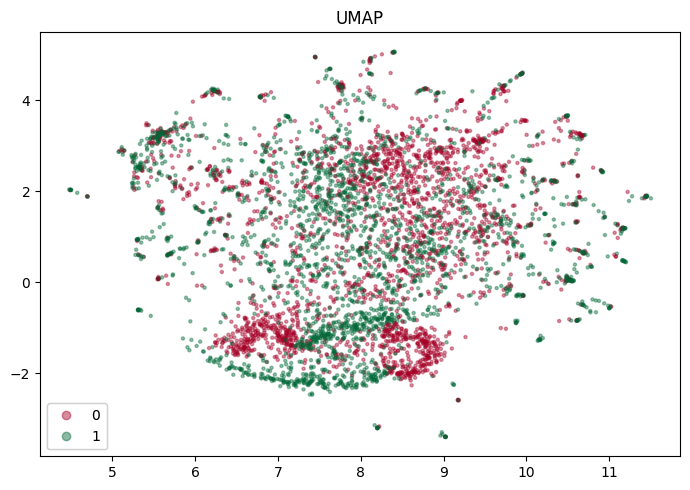

In [10]:
fig, ax = plt.subplots(figsize=(7,5))
scatter = ax.scatter(coordinates[:,0],coordinates[:,1],c=y[::10],s=5,alpha=0.4,cmap='RdYlGn')

ax.set_title('UMAP')
legend1 = ax.legend(*scatter.legend_elements(),loc="lower left")
ax.add_artist(legend1)

plt.tight_layout()
plt.savefig("umap_vis.png", dpi=150)
plt.show()

# Logistic regression

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)

In [12]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [13]:
y_pred = model.predict(X_test)

In [14]:
accuracy = accuracy_score(y_test, y_pred)
print(f"accuracy: {round(accuracy,2)}")
print("Classification Report:\n", classification_report(y_test, y_pred))

accuracy: 0.89
Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.88      0.89      4899
           1       0.88      0.91      0.89      5018

    accuracy                           0.89      9917
   macro avg       0.89      0.89      0.89      9917
weighted avg       0.89      0.89      0.89      9917



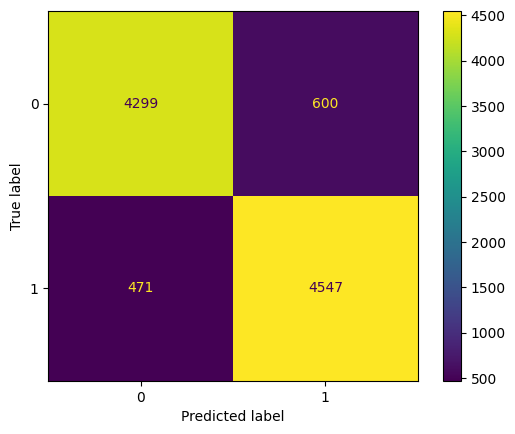

In [15]:
cm = confusion_matrix(y_test, y_pred)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = [0, 1])

cm_display.plot()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

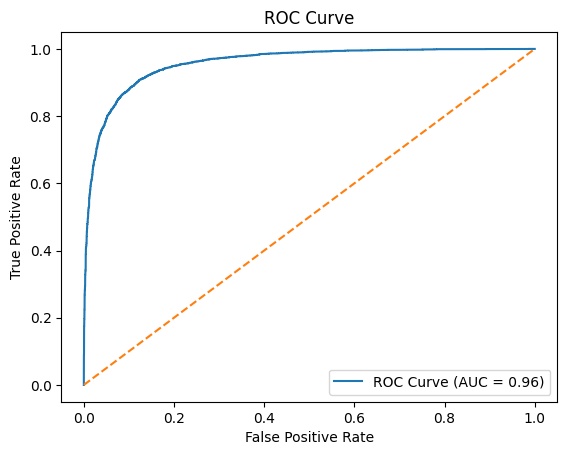

In [16]:
y_prob = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.savefig("roc_curve.png", dpi=150)
plt.show()